### Research Question: Loan Default Prediction

**Can we predict whether a borrower will default on a loan based on their financial and personal information?**

Our goal is to understand which borrower characteristics are related to loan defaults and use machine learning models to predict whether someone is likely to default. We will use information such as income, credit score, loan amount, interest rate, age, and employment history.

Our target variable is `Default`, which has two possible values:

- **Default = 0:** The borrower did not default on the loan (did not fail to repay as required).
- **Default = 1:** The borrower defaulted on the loan (failed to repay as required).

We will compare different models to see which one is better at identifying borrowers who may be at risk of default.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Loan_default.csv")
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
print("Rows and columns:", df.shape)

df.info()

Rows and columns: (255347, 18)
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df["LoanID"].duplicated().sum()

np.int64(0)

In [6]:
df.dtypes

LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,255347.0,43.498306,14.990258,18.0,31.00,43.00,56.00,69.0
Income,255347.0,82499.304597,38963.013729,15000.0,48825.50,82466.00,116219.00,149999.0
LoanAmount,255347.0,127578.865512,70840.706142,5000.0,66156.00,127556.00,188985.00,249999.0
CreditScore,255347.0,574.264346,158.903867,300.0,437.00,574.00,712.00,849.0
MonthsEmployed,255347.0,59.541976,34.643376,0.0,30.00,60.00,90.00,119.0
NumCreditLines,255347.0,2.501036,1.117018,1.0,2.00,2.00,3.00,4.0
InterestRate,255347.0,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0
LoanTerm,255347.0,36.025894,16.969330,12.0,24.00,36.00,48.00,60.0
DTIRatio,255347.0,0.500212,0.230917,0.1,0.30,0.50,0.70,0.9
Default,255347.0,0.116128,0.320379,0.0,0.00,0.00,0.00,1.0


In [8]:
categorical_cols = [
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


Education:
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

EmploymentType:
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

HasMortgage:
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

HasDependents:
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

LoanPurpose:
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

HasCoSigner:
HasCoSigner
Yes    127701
No     127646
Name: count, dtype: int64


**Data Cleaning and Feature Engineering**

In [9]:
# Make a copy so the original data stays unchanged
df_clean = df.copy()

In [10]:
# Remove LoanID because it is only an identifier
df_clean = df_clean.drop(columns=["LoanID"])

In [11]:

# Rename DTIRatio to make its meaning clearer
df_clean = df_clean.rename(columns={
    "DTIRatio": "DebtToIncomeRatio"
})
# Example: $1,500 monthly debt / $5,000 monthly income = 0.30 (30% DTI).
# DebtToIncomeRatio (DTI) shows how much of a borrower's income goes toward debt payments.
# A higher ratio means more income is used to pay debts, which may increase the risk of loan default




In [12]:
# Compare the loan amount with the borrower's annual income
df_clean["LoanToIncomeRatio"] = (
    df_clean["LoanAmount"] / df_clean["Income"]
)
# LoanToIncomeRatio: Tells us how large the borrower's loan is compared to their annual income.
# Example: $100,000 loan / $50,000 annual income = 2.0.

# Check the first five results
df_clean[["LoanAmount", "Income", "LoanToIncomeRatio"]].head()


,LoanAmount,Income,LoanToIncomeRatio
0,50587,85994,0.588262
1,124440,50432,2.467481
2,129188,84208,1.534154
3,44799,31713,1.412638
4,9139,20437,0.447179


In [13]:
# Check the number of rows and columns
print("Shape:", df_clean.shape)

# Check for missing values
print("Missing values:", df_clean.isnull().sum().sum())

# Check for duplicate rows
print("Duplicates:", df_clean.duplicated().sum())

# Check the first five rows
display(df_clean.head())

Shape: (255347, 18)
Missing values: 0
Duplicates: 0


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DebtToIncomeRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default,LoanToIncomeRatio
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0,0.588262
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0,2.467481
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1,1.534154
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0,1.412638
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0,0.447179


In [14]:
# Save the cleaned dataset
df_clean.to_csv("Loan_default_cleaned.csv", index=False)

**Exploratory Data Analysis (EDA)**

*Loan Default Distribution*

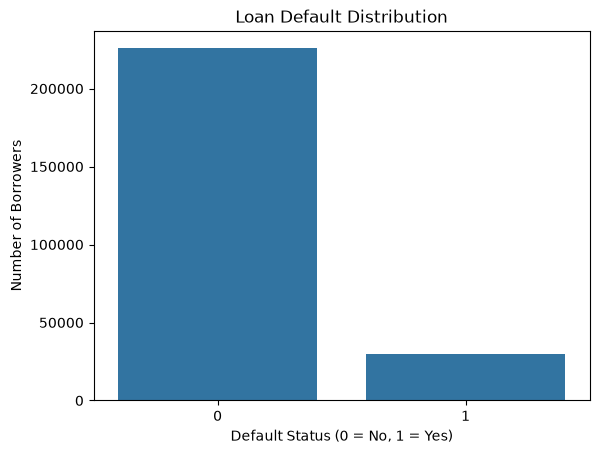

In [15]:
# Count borrowers who defaulted and did not default
default_counts = df_clean["Default"].value_counts().sort_index()

# Create a bar chart
sns.countplot(data=df_clean, x="Default")

# Add labels
plt.title("Loan Default Distribution")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Borrowers")

plt.show()

Credit Score and Loan Default
Do borrowers with lower credit scores have a higher chance of defaulting?

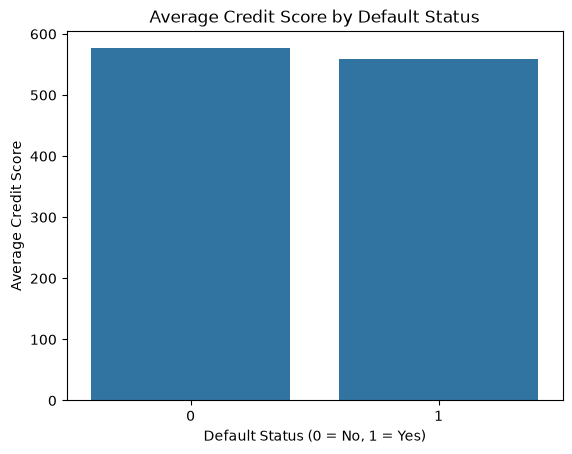

In [16]:
# Find the average credit score for each default group
avg_credit = df_clean.groupby("Default")["CreditScore"].mean()

# Create a bar chart
sns.barplot(data=df_clean, x="Default", y="CreditScore", errorbar=None)

# Add labels
plt.title("Average Credit Score by Default Status")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Average Credit Score")

plt.show()

The graph shows that borrowers who defaulted had slightly lower credit scores than those who did not. This means people with lower credit scores may be more likely to default, but the difference is small.

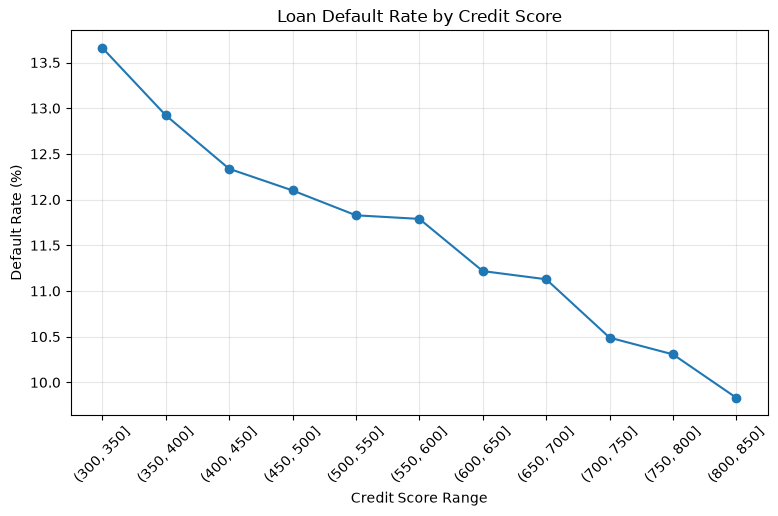

In [17]:
# Group credit scores into ranges of 50 points
df_clean["CreditScoreGroup"] = pd.cut(
    df_clean["CreditScore"],
    bins=range(300, 901, 50)
)

# Calculate the default rate for each credit score group
credit_default = df_clean.groupby(
    "CreditScoreGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(9, 5))
plt.plot(credit_default.index.astype(str), credit_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Credit Score")
plt.xlabel("Credit Score Range")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

The graph shows that borrowers with lower credit scores have higher default rates. As credit scores increase, the default rate decreases from about 13.7% to 9.8%. This suggests that credit score may help us predict loan defaults.

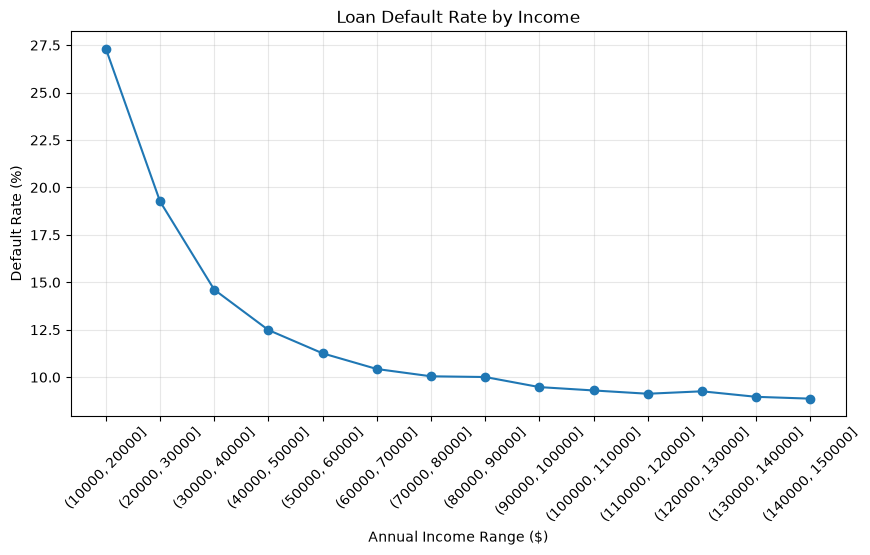

In [18]:
# Divide income into ranges of $10,000
df_clean["IncomeGroup"] = pd.cut(
    df_clean["Income"],
    bins=range(10000, 160001, 10000)
)

# Calculate the default rate for each income group
income_default = df_clean.groupby(
    "IncomeGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(10, 5))
plt.plot(income_default.index.astype(str),
         income_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Income")
plt.xlabel("Annual Income Range ($)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

The graph shows that borrowers with lower incomes have higher default rates. As income increases, the default rate decreases, especially for lower-income borrowers. This suggests that income may be an important factor in predicting loan defaults.

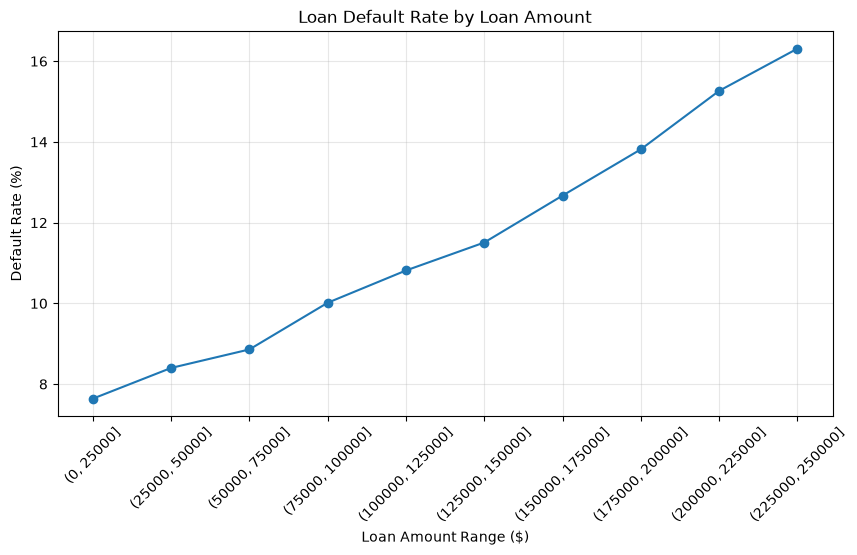

In [19]:
# Divide loan amounts into ranges of $25,000
df_clean["LoanAmountGroup"] = pd.cut(
    df_clean["LoanAmount"],
    bins=range(0, 275001, 25000)
)

# Calculate the default rate for each loan amount group
loan_default = df_clean.groupby(
    "LoanAmountGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(10, 5))
plt.plot(loan_default.index.astype(str),
         loan_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Loan Amount")
plt.xlabel("Loan Amount Range ($)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

The graph shows that borrowers with larger loan amounts have higher default rates. The default rate increases from about 7.6% for smaller loans to 16.3% for larger loans. This suggests that loan amount may be an important factor in predicting loan defaults.

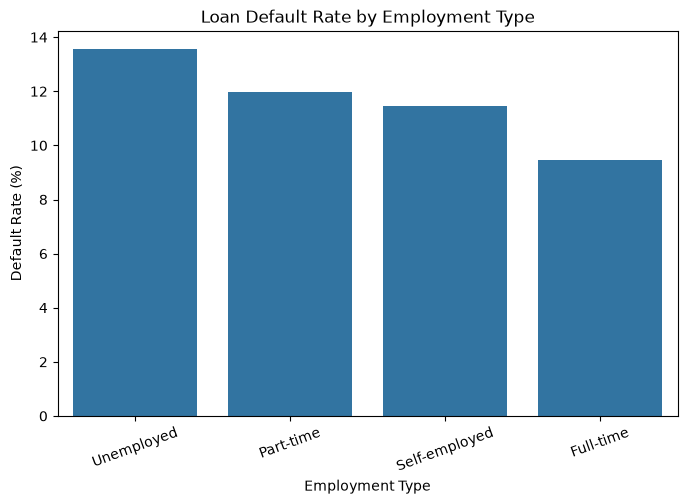

In [20]:
# Calculate the default rate for each employment type
employment_default = (
    df_clean.groupby("EmploymentType")["Default"].mean() * 100
)

# Sort from highest to lowest default rate
employment_default = employment_default.sort_values(ascending=False)

# Create a bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=employment_default.index, y=employment_default.values)

# Add labels
plt.title("Loan Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)

plt.show()

Unemployed borrowers have the highest default rate, while full-time employees have the lowest.

This suggests that employment type may be related to loan default risk.

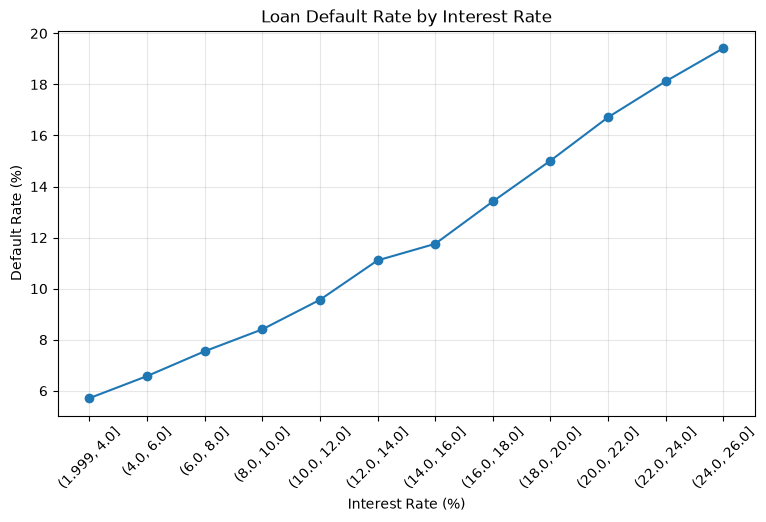

In [21]:
# Divide interest rates into groups of 2 percentage points
df_clean["InterestRateGroup"] = pd.cut(
    df_clean["InterestRate"],
    bins=range(2, 28, 2),
    include_lowest=True
)

# Calculate the default rate for each interest rate group
interest_default = df_clean.groupby(
    "InterestRateGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(9, 5))
plt.plot(interest_default.index.astype(str),
         interest_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Interest Rate")
plt.xlabel("Interest Rate (%)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

The graph shows that borrowers with higher interest rates have higher default rates. The default rate increases from about 5.8% to 19.4% as interest rates increase. This suggests that interest rate may be an important factor in predicting loan defaults.

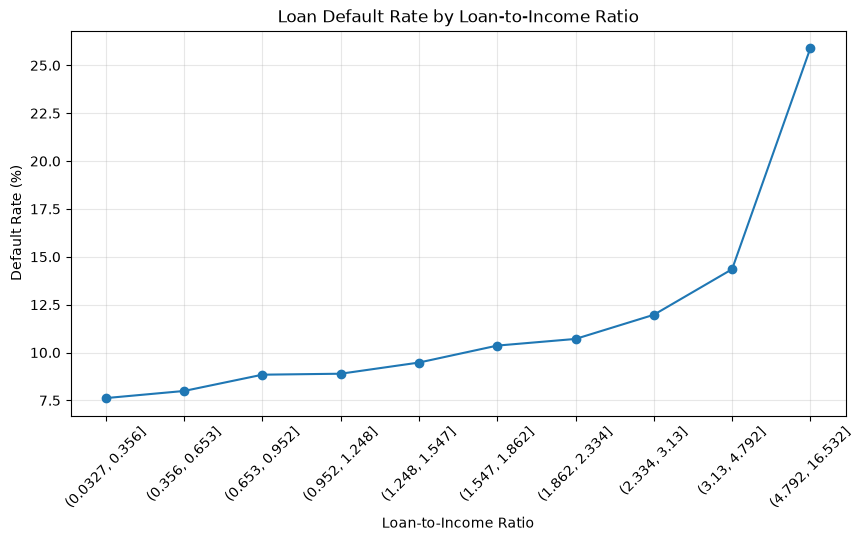

In [22]:
# Divide loan-to-income ratios into 10 groups
df_clean["LoanToIncomeGroup"] = pd.qcut(
    df_clean["LoanToIncomeRatio"],
    q=10,
    duplicates="drop"
)

# Calculate the default rate for each group
ratio_default = df_clean.groupby(
    "LoanToIncomeGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(10, 5))
plt.plot(ratio_default.index.astype(str),
         ratio_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Loan-to-Income Ratio")
plt.xlabel("Loan-to-Income Ratio")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

The graph shows that people who borrow more money compared to their income are more likely to default on their loans. The default rate increases from about 7.6% to 26%. This means the loan-to-income ratio could help us predict loan defaults.

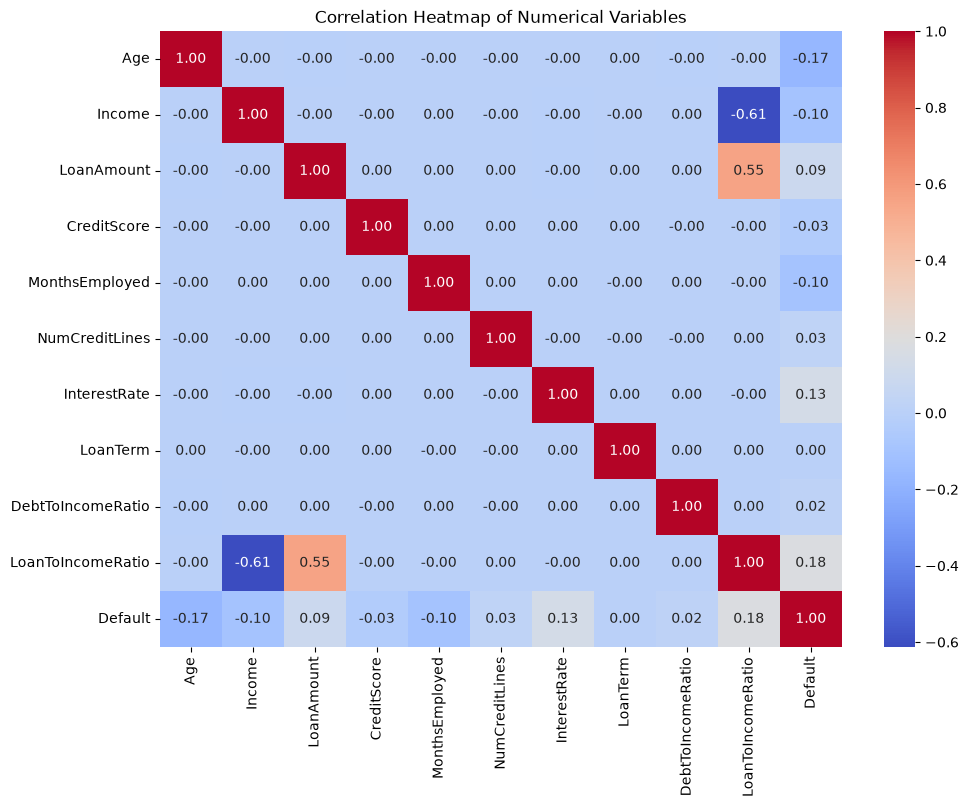

In [23]:
# Select the original numerical variables and our new feature
numeric_cols = [
    "Age", "Income", "LoanAmount", "CreditScore",
    "MonthsEmployed", "NumCreditLines", "InterestRate",
    "LoanTerm", "DebtToIncomeRatio", "LoanToIncomeRatio",
    "Default"
]

# Calculate correlations
corr = df_clean[numeric_cols].corr()

# Create a heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

# Add a title
plt.title("Correlation Heatmap of Numerical Variables")

plt.show()

The heatmap shows that loan-to-income ratio, age, and interest rate have the strongest relationships with loan default among the numerical variables. People with larger loans compared to their income, younger borrowers, and those with higher interest rates tend to have higher default rates. but these relationships are not very strong.

## Deeper EDA: When do borrowers have higher default rates?

**Question:** Do age and interest rate together show differences in loan default rates?

We already looked at these variables separately. Here we compare them together to find groups with higher or lower default rates. The values show the percentage of borrowers who defaulted in each group, not proof that either factor causes default.

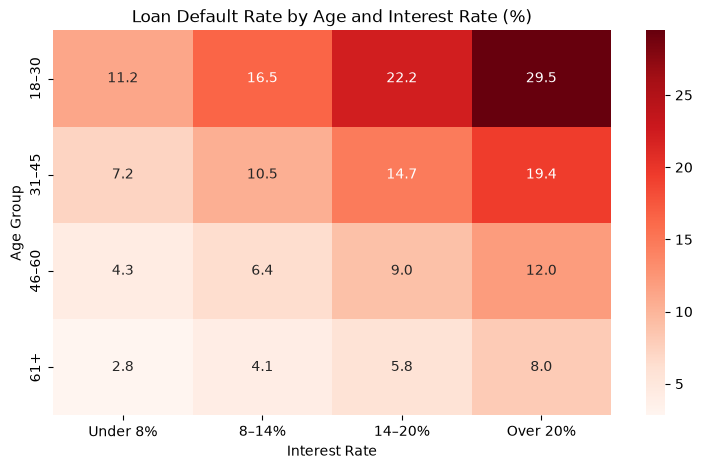

In [24]:
# Make age and interest rate groups for this chart only
eda_risk = df_clean.copy()
eda_risk["AgeGroup"] = pd.cut(
    eda_risk["Age"], bins=[17, 30, 45, 60, 100],
    labels=["18–30", "31–45", "46–60", "61+"]
)
eda_risk["RateGroup"] = pd.cut(
    eda_risk["InterestRate"], bins=[0, 8, 14, 20, 100],
    labels=["Under 8%", "8–14%", "14–20%", "Over 20%"]
)

# Calculate the default rate for each combination
risk_table = eda_risk.pivot_table(
    index="AgeGroup", columns="RateGroup", values="Default",
    aggfunc="mean", observed=True
) * 100

# Plot the default rates
plt.figure(figsize=(9, 5))
sns.heatmap(risk_table, annot=True, fmt=".1f", cmap="Reds")
plt.title("Loan Default Rate by Age and Interest Rate (%)")
plt.xlabel("Interest Rate")
plt.ylabel("Age Group")
plt.show()

### Interpretation: Loan Default Rate by Age and Interest Rate

The heatmap shows that younger borrowers with higher interest rates are more likely to default on their loans. Borrowers aged 18–30 with interest rates over 20% have the highest default rate of 29.5%. In comparison, borrowers aged 61 and older with interest rates under 8% have the lowest default rate of 2.8%. We can also see that default rates increase as interest rates increase, but decrease as borrowers get older. This shows that both age and interest rate are related to loan default risk.

### How does the number of risk indicators relate to default?

**Question:** Are borrowers with more risk indicators more likely to default?

For this exploratory chart, we count four simple indicators: younger age, lower income, higher interest rate, and a larger loan compared with income. The cutoffs are examples for exploration, not bank lending rules.

,RiskCount,DefaultRate,Borrowers
0,0,5.05,76906
1,1,9.78,98402
2,2,16.44,53044
3,3,24.83,22825
4,4,42.25,4170


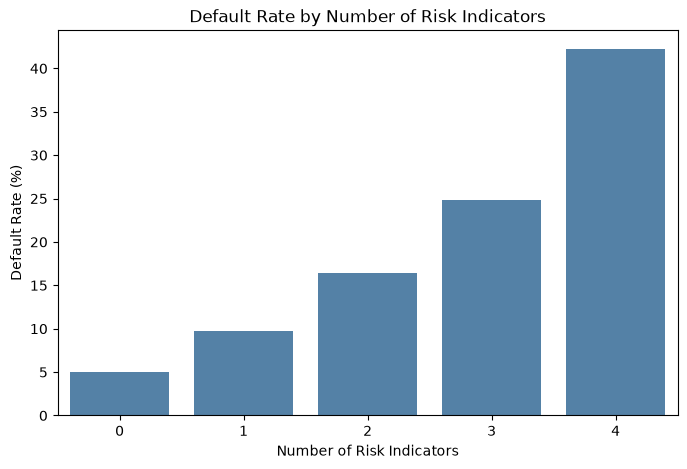

In [25]:
# Count simple risk indicators (exploratory cutoffs)
eda_risk["RiskCount"] = (
    (eda_risk["Age"] < 30).astype(int)
    + (eda_risk["Income"] < 50000).astype(int)
    + (eda_risk["InterestRate"] >= 15).astype(int)
    + (eda_risk["LoanToIncomeRatio"] >= 3).astype(int)
)

# Compare default rates by the number of indicators
risk_summary = eda_risk.groupby("RiskCount")["Default"].agg(
    DefaultRate="mean", Borrowers="size"
).reset_index()
risk_summary["DefaultRate"] *= 100
display(risk_summary.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(data=risk_summary, x="RiskCount", y="DefaultRate", color="steelblue")
plt.title("Default Rate by Number of Risk Indicators")
plt.xlabel("Number of Risk Indicators")
plt.ylabel("Default Rate (%)")
plt.show()

The graph shows that borrowers with more risk indicators are more likely to default on their loans. Borrowers with no risk indicators have a default rate of 5.05%, while those with all four have a default rate of 42.25%. This shows that having more risk indicators is associated with a higher chance of loan default.

We will use Multiple Linear Regression to answer the question: Can we predict a borrower's credit score using their financial and personal information? We will use variables such as age, income, loan amount, and employment history to predict credit scores. We are using this model to see how these factors are related to credit scores and how accurately we can predict them. We will evaluate the model using R², RMSE, and an actual vs. predicted graph.

In [26]:
# Import tools for splitting data and building the model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import mean_absolute_error

In [27]:
# Select the information we will use to predict credit scores
features = [
    "Age",
    "Income",
    "LoanAmount",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DebtToIncomeRatio",
    "LoanToIncomeRatio"
]

# X contains our predictors
X = df_clean[features]

# y is the value we want to predict
y = df_clean["CreditScore"]

# Check the first five rows
X.head()

,Age,Income,LoanAmount,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DebtToIncomeRatio,LoanToIncomeRatio
0,56,85994,50587,80,4,15.23,36,0.44,0.588262
1,69,50432,124440,15,1,4.81,60,0.68,2.467481
2,46,84208,129188,26,3,21.17,24,0.31,1.534154
3,32,31713,44799,0,3,7.07,24,0.23,1.412638
4,60,20437,9139,8,4,6.51,48,0.73,0.447179


In [28]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Check the number of rows in each set
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 204277
Testing rows: 51070


In [29]:
# Create the linear regression model
linear_model = LinearRegression()

# Train the model using the training data
linear_model.fit(X_train, y_train)

# Predict credit scores for the testing data
y_pred = linear_model.predict(X_test)

# Show the first five predictions
print("Predicted credit scores:", y_pred[:5])

Predicted credit scores: [573.8855961  574.07172748 574.40615433 574.19040385 574.73999643]


In [30]:
# Calculate R-squared
r2 = r2_score(y_test, y_pred)

# Calculate Root Mean Squared Error
rmse = mean_squared_error(y_test, y_pred) ** 0.5

# Show the results
print("R-squared:", round(r2, 4))
print("RMSE:", round(rmse, 2))

R-squared: -0.0001
RMSE: 159.01


In [31]:
# Load the cleaned dataset
df_model = pd.read_csv("Loan_default_cleaned.csv")

# Separate predictors and target
X = df_model.drop(columns=["CreditScore", "Default"])
y = df_model["CreditScore"]

# Convert categorical variables into dummy variables
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Check the new columns
X.head()

,Age,Income,LoanAmount,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DebtToIncomeRatio,LoanToIncomeRatio,Education_High School,...,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other,HasCoSigner_Yes
0,56,85994,50587,80,4,15.23,36,0.44,0.588262,0,...,0,0,0,1,1,0,0,0,1,1
1,69,50432,124440,15,1,4.81,60,0.68,2.467481,0,...,0,1,0,0,0,0,0,0,1,1
2,46,84208,129188,26,3,21.17,24,0.31,1.534154,0,...,1,0,0,1,1,0,0,0,0,0
3,32,31713,44799,0,3,7.07,24,0.23,1.412638,1,...,0,1,0,0,0,1,0,0,0,0
4,60,20437,9139,8,4,6.51,48,0.73,0.447179,0,...,1,0,0,0,1,0,0,0,0,0


In [32]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=True,
    random_state=42
)

# Train the model
linear_model_dummy = LinearRegression()
linear_model_dummy.fit(X_train, y_train)

# Predict credit scores
y_pred_dummy = linear_model_dummy.predict(X_test)

# Calculate model performance
r2_dummy = r2_score(y_test, y_pred_dummy)
rmse_dummy = mean_squared_error(y_test, y_pred_dummy) ** 0.5
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)

# Display results
print("R-squared:", round(r2_dummy, 4))
print("RMSE:", round(rmse_dummy, 2))
print("MAE:", round(mae_dummy, 2))

R-squared: -0.0003
RMSE: 159.03
MAE: 137.65


The model has an R² of -0.0003, an RMSE of 159.03, and an MAE of 137.65. This means our model does not predict credit scores well. On average, its predictions are about 138 points away from the actual credit scores. Adding categorical variables did not improve the model's performance.

We used Polynomial Regression to see if it can predict credit scores better than Multiple Linear Regression. Instead of only looking at straight-line relationships, Polynomial Regression can capture curved relationships between borrower characteristics and credit scores. We want to see if these curved relationships help improve our predictions.

In [50]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Select numerical predictors
X = df_model[
    ["Age", "Income", "LoanAmount", "MonthsEmployed",
     "InterestRate", "DebtToIncomeRatio"]
]

# Select the target
y = df_model["CreditScore"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=True,
    random_state=42
)

# Create a polynomial regression model
poly_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train the model
poly_model.fit(X_train, y_train)

# Predict credit scores
y_pred_poly = poly_model.predict(X_test)

# Evaluate the model
print("R-squared:", round(r2_score(y_test, y_pred_poly), 4))
print("RMSE:", round(mean_squared_error(y_test, y_pred_poly) ** 0.5, 2))
print("MAE:", round(mean_absolute_error(y_test, y_pred_poly), 2))


R-squared: -0.0001
RMSE: 159.02
MAE: 137.65


We used Polynomial Regression with degree 2 to see if curved relationships between borrower characteristics and credit scores could improve our predictions. We also used StandardScaler to put all numerical variables on a similar scale because some variables, like Income and LoanAmount, have much larger values than others. This helps the model make more reliable calculations.

### Cross-Validation: Comparing Regression Models

**Question:** Which model predicts credit scores better, Linear Regression or Polynomial Regression?

We will use 5-fold cross-validation to compare the two models. We are doing this because our previous models had poor results, and we want to see which model performs better on different parts of the data. We will compare their average RMSE and standard deviation. A lower RMSE means better predictions, while a lower standard deviation means more consistent results.

In [53]:
# Import the libraries

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline

# Select the predictors
features = [
    "Age", "Income", "LoanAmount",
    "MonthsEmployed", "InterestRate",
    "DebtToIncomeRatio"
]

X = df_model[features]
y = df_model["CreditScore"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42
)

# Create the Linear Regression model
linear_model_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Create the Polynomial Regression model
poly_model_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])

In [54]:
# Create 5 folds
cv = KFold(n_splits=5, shuffle=True, random_state=123)

# Store the models
models = {
    "Linear Regression": linear_model_cv,
    "Polynomial Regression": poly_model_cv
}

# Store the results
results = []

# Test each model using cross-validation
for name, model in models.items():

    scores = -cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    results.append({
        "Model": name,
        "Mean RMSE": scores.mean(),
        "SD RMSE": scores.std()
    })

# Show the results
cv_results = pd.DataFrame(results)
display(cv_results.round(2))

,Model,Mean RMSE,SD RMSE
0,Linear Regression,158.88,0.14
1,Polynomial Regression,158.89,0.13


We used 5-fold cross-validation to compare Linear Regression and Polynomial Regression. Linear Regression had a slightly lower average RMSE (158.88) than Polynomial Regression (158.89), while Polynomial Regression had a slightly lower standard deviation (0.13 compared to 0.14). The differences were very small, so both models performed almost the same. We chose Linear Regression because it is simpler and adding curved relationships did not improve our predictions.

In [56]:
# Import the evaluation tools
from sklearn.base import clone

# Make a copy of the selected model
best_model = clone(linear_model_cv)

# Train the model
best_model.fit(X_train, y_train)

# Predict credit scores on the test data
y_pred_final = best_model.predict(X_test)

# Calculate the test results
test_rmse = mean_squared_error(y_test, y_pred_final) ** 0.5
test_r2 = r2_score(y_test, y_pred_final)

# Show the results
print("Test RMSE:", round(test_rmse, 2))
print("Test R-squared:", round(test_r2, 4))

Test RMSE: 159.02
Test R-squared: -0.0001


We selected Linear Regression after comparing it with Polynomial Regression using 5-fold cross-validation. The final model had an RMSE of 159.02 and an R² of -0.0001 on the test data. The test RMSE was close to the cross-validation RMSE of 158.88, showing that the model performed consistently. However, the R² was almost zero, meaning the model could not explain the differences in borrowers' credit scores. This suggests that the available variables are not useful for accurately predicting credit scores with Linear Regression.

## Logistic Regression

**Question:** Can we predict whether a borrower will default on a loan using their financial and personal information?

We will use Logistic Regression to predict whether a borrower will default (1) or not default (0). We are using this model because our target variable has two possible outcomes. The model will use information such as income, age, loan amount, credit score, and employment history to estimate the probability of default. We will evaluate the model using accuracy, precision, recall, F1-score, and ROC-AUC to see how well it identifies borrowers who may default.

In [57]:
# Load the cleaned dataset
df_model = pd.read_csv("Loan_default_cleaned.csv")

# Select the predictors and target
X = df_model.drop(columns=["Default"])
y = df_model["Default"]

# Convert categorical variables into dummy variables
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Check the predictors
X.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DebtToIncomeRatio,LoanToIncomeRatio,...,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other,HasCoSigner_Yes
0,56,85994,50587,520,80,4,15.23,36,0.44,0.588262,...,0,0,0,1,1,0,0,0,1,1
1,69,50432,124440,458,15,1,4.81,60,0.68,2.467481,...,0,1,0,0,0,0,0,0,1,1
2,46,84208,129188,451,26,3,21.17,24,0.31,1.534154,...,1,0,0,1,1,0,0,0,0,0
3,32,31713,44799,743,0,3,7.07,24,0.23,1.412638,...,0,1,0,0,0,1,0,0,0,0
4,60,20437,9139,633,8,4,6.51,48,0.73,0.447179,...,1,0,0,0,1,0,0,0,0,0


Logistic Regression needs numerical inputs, so we convert categorical variables such as employment type and education into dummy variables.

In [58]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=True,
    stratify=y,
    random_state=42
)

# Check the number of rows
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Check the default rate in each set
print("Training default rate:", round(y_train.mean(), 4))
print("Testing default rate:", round(y_test.mean(), 4))

Training rows: 204277
Testing rows: 51070
Training default rate: 0.1161
Testing default rate: 0.1161


In [59]:
# Import the model and preprocessing tools
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Create the Logistic Regression model
log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Train the model
log_model.fit(X_train, y_train)

# Predict loan defaults
y_pred_log = log_model.predict(X_test)

# Predict default probabilities
y_prob_log = log_model.predict_proba(X_test)[:, 1]

In [60]:
# Import evaluation tools
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate model performance
accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log, zero_division=0)
recall = recall_score(y_test, y_pred_log, zero_division=0)
f1 = f1_score(y_test, y_pred_log, zero_division=0)
auc = roc_auc_score(y_test, y_prob_log)

# Display the results
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("ROC-AUC:", round(auc, 4))

Accuracy: 0.8869
Precision: 0.614
Recall: 0.0695
F1-score: 0.1248
ROC-AUC: 0.7617


Our Logistic Regression model achieved an accuracy of 88.69% and a ROC-AUC of 0.7617, showing that it can distinguish between borrowers with different levels of default risk. However, recall was only 6.95%, meaning the model missed most borrowers who actually defaulted. Although precision was 61.40%, the low recall resulted in a low F1-score of 12.48%. Since our goal is to identify borrowers who may default, we need to improve recall.

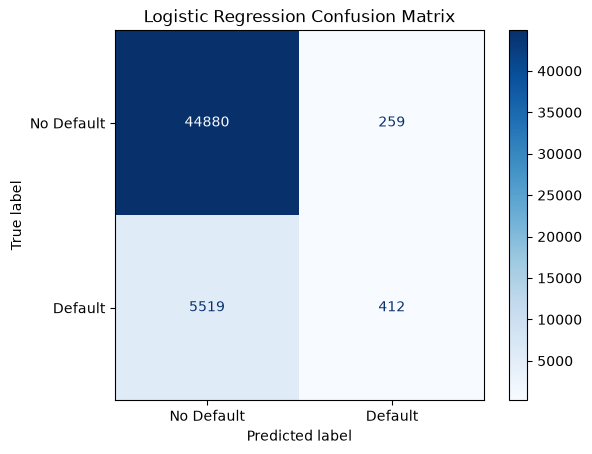

In [41]:
# Import the plotting tools
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_log,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    values_format="d"
)

# Add a title
plt.title("Logistic Regression Confusion Matrix")
plt.show()

The confusion matrix shows that our Logistic Regression model correctly predicted 44,880 borrowers who did not default and 412 borrowers who defaulted. However, it missed 5,519 borrowers who actually defaulted and incorrectly predicted 259 borrowers would default. This explains why our accuracy is high but recall is very low. Since our goal is to identify borrowers who may default, we need to improve recall.

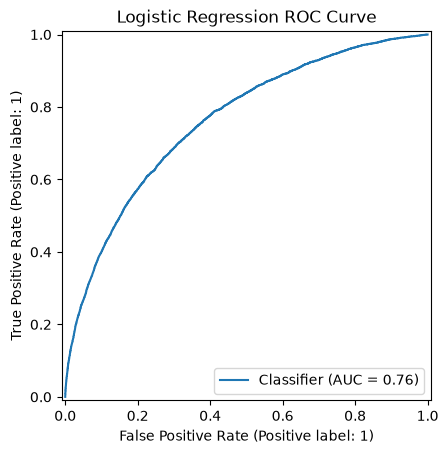

In [42]:
# Import ROC curve tools
from sklearn.metrics import RocCurveDisplay

# Plot the ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_log
)

# Add a title
plt.title("Logistic Regression ROC Curve")
plt.show()

The ROC curve shows how well our Logistic Regression model distinguishes between borrowers who default and those who do not. Our model achieved an AUC of 0.76, which indicates a reasonable ability to identify borrowers at risk of default. The curve is above the random-guessing line, showing that our model performs better than random guessing. However, the model is not perfect and may still incorrectly classify some borrowers.

In [43]:
# Exploratory comparison on the test set (not for choosing a final threshold)
# Test different probability thresholds
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

# Store the results
results = []

for threshold in thresholds:

    # Predict defaults using the threshold
    y_pred_threshold = (y_prob_log >= threshold).astype(int)

    # Calculate evaluation metrics
    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1-score": f1_score(y_test, y_pred_threshold)
    })

# Show the results
threshold_results = pd.DataFrame(results)
display(threshold_results.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.5,0.8869,0.6140,0.0695,0.1248
1,0.4,0.8856,0.5303,0.1344,0.2144
2,0.3,0.8748,0.4321,0.2475,0.3148
3,0.2,0.8257,0.3206,0.4473,0.3735
4,0.1,0.6410,0.2097,0.7554,0.3283


Selecting the Best Probability Threshold

Question: Which probability threshold gives the best balance between precision and recall?

We tested different thresholds and found that 0.2 had the highest F1-score. Now we will use validation data to select a threshold without relying on the test results. We want to improve our model's ability to identify borrowers who default while keeping incorrect predictions as low as possible.

In [61]:
# Split the training data into training and validation sets
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    shuffle=True,
    stratify=y_train,
    random_state=42
)

# Train a new model using the smaller training set
log_model_val = clone(log_model)
log_model_val.fit(X_train_new, y_train_new)

# Predict probabilities for the validation data
y_prob_val = log_model_val.predict_proba(X_val)[:, 1]

In [63]:
# Test different thresholds
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

# Store the results
val_results = []

for threshold in thresholds:

    # Predict defaults using each threshold
    y_pred_val = (y_prob_val >= threshold).astype(int)

    # Calculate model performance
    val_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred_val, zero_division=0),
        "Recall": recall_score(y_val, y_pred_val),
        "F1-score": f1_score(y_val, y_pred_val)
    })

# Show the results
val_results = pd.DataFrame(val_results)
display(val_results.round(4))

,Threshold,Precision,Recall,F1-score
0,0.5,0.5992,0.0662,0.1192
1,0.4,0.5317,0.1290,0.2076
2,0.3,0.4249,0.2390,0.3059
3,0.2,0.3148,0.4304,0.3636
4,0.1,0.2063,0.7350,0.3222


We tested different thresholds using validation data to see which one worked best. The threshold of 0.2 had the highest F1-score of 0.3636, with 31.48% precision and 43.04% recall. This helped our model find more borrowers who defaulted, but it also made more incorrect predictions. We chose 0.2 because it gave the best balance between precision and recall.

In [64]:
# Select the best threshold
best_threshold = val_results.loc[val_results["F1-score"].idxmax(), "Threshold"]

# Train the model on the full training data
log_model.fit(X_train, y_train)

# Predict probabilities on the test data
y_prob_final = log_model.predict_proba(X_test)[:, 1]

# Predict defaults using threshold 0.2
y_pred_final_log = (y_prob_final >= best_threshold).astype(int)

# Calculate final evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_final_log), 4))
print("Precision:", round(precision_score(y_test, y_pred_final_log), 4))
print("Recall:", round(recall_score(y_test, y_pred_final_log), 4))
print("F1-score:", round(f1_score(y_test, y_pred_final_log), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_final), 4))

Accuracy: 0.8257
Precision: 0.3206
Recall: 0.4473
F1-score: 0.3735
ROC-AUC: 0.7617


We evaluated our final Logistic Regression model on the test dataset using the threshold selected from the validation results. The model achieved an accuracy of 82.57%, precision of 32.06%, recall of 44.73%, F1-score of 37.35%, and ROC-AUC of 0.7617. Although the accuracy was relatively high, the model correctly identified only 44.73% of actual loan defaults. The low precision also shows that many borrowers predicted to default did not actually default. Overall, the model showed a reasonable ability to distinguish between borrowers who default and those who do not, but it still missed many actual defaults